# Generate interferograms and map the lava flow emplacement using OPERA CSLC-S1

---    

### Data Used in the Example:   

- **10 meter (Northing) x 5 meter (Easting) North America OPERA Coregistered Single Look Complex from Sentinel-1 products**
    - This dataset contains Level-2 OPERA coregistered single-look-complex (CSLC) data from Sentinel-1 (S1). <span style="color:red"> The data in this example are geocoded CSLC-S1 data covering Mauna Loa volcano in the Big Island, Hawaii</span>. 
    
    - The OPERA project is generating geocoded burst-wise CSLC-S1 products over North America which includes USA and US Territories within 200 km from the US border, Canada, and all mainland countries from the southern US border down to and including Panama. Each pixel within a burst SLC is represented by a complex number and contains both the amplitude and phase information. The CSLC-S1 products are distributed over projected map coordinates using the Universal Transverse Mercator (UTM) projection with spacing in the X- and Y-directions of 5 m and 10 m, respectively. Each OPERA CSLC-S1 product is distributed as a HDF5 file following the CF-1.8 convention with separate groups containing the data raster layers, the low-resolution correction layers, and relevant product metadata.

    - For more information about the OPERA project and other products please visit our website at https://www.jpl.nasa.gov/go/opera .

Please refer to the [OPERA Product Specification Document](https://d2pn8kiwq2w21t.cloudfront.net/documents/ProductSpec_CSLC_URS314199.pdf) for details about the CSLC-S1 product.

*Prepared by M. Grace Bato*

---

## 0. Setup your conda environment

Assuming you have [miniconda](https://docs.conda.io/projects/miniconda/en/latest/miniconda-install.html) or conda installed. Open your terminal and run the following:
```
> conda create -n opera_cslc python=3.11 --yes
> conda activate opera_cslc
> conda install -c conda-forge mamba --yes
> mamba env update -p ${CONDA_PREFIX} --file "opera_cslc_env.yml"
```

---    

## 1. Load Python modules

In [1]:
## Load necessary modules

import asf_search as asf
import geopandas as gpd
import pandas as pd

import h5py
from netrc import netrc
from subprocess import Popen
from platform import system
from getpass import getpass
import folium
import datetime as dt
from shapely.geometry import box
from shapely.geometry import Point
import shapely.wkt as wkt
import rioxarray
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import cartopy.crs as ccrs
import xarray as xr
import rasterio
from rasterio.transform import from_origin
from rasterio import merge
from rasterio.crs import CRS

import os

In [2]:
## Load plotting module
import matplotlib.pyplot as plt
%matplotlib inline
%config InlineBackend.figure_format='retina'

In [3]:
## Load pandas and setup config to expand the display of the database
import pandas as pd
# pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)

In [4]:
## Avoid lots of these warnings printing to notebook from asf_search
import warnings
warnings.filterwarnings('ignore')

## 2. Set up your NASA Earthdata Login Credentials

In [5]:
# Generates authentication token
# Asks for your Earthdata username and password for first time, if netrc does not exists.

urs = 'urs.earthdata.nasa.gov'    # Earthdata URL endpoint for authentication
prompts = ['Enter NASA Earthdata Login Username: ',
           'Enter NASA Earthdata Login Password: ']

# Determine the OS (Windows machines usually use an '_netrc' file)
netrc_name = "_netrc" if system()=="Windows" else ".netrc"

# Determine if netrc file exists, and if so, if it includes NASA Earthdata Login Credentials
try:
    netrcDir = os.path.expanduser(f"~/{netrc_name}")
    netrc(netrcDir).authenticators(urs)[0]

# Below, create a netrc file and prompt user for NASA Earthdata Login Username and Password
except FileNotFoundError:
    homeDir = os.path.expanduser("~")
    Popen('touch {0}{2} | echo machine {1} >> {0}{2}'.format(homeDir + os.sep, urs, netrc_name), shell=True)
    Popen('echo login {} >> {}{}'.format(getpass(prompt=prompts[0]), homeDir + os.sep, netrc_name), shell=True)
    Popen('echo \'password {} \'>> {}{}'.format(getpass(prompt=prompts[1]), homeDir + os.sep, netrc_name), shell=True)
    # Set restrictive permissions
    Popen('chmod 0600 {0}{1}'.format(homeDir + os.sep, netrc_name), shell=True)

    # Determine OS and edit netrc file if it exists but is not set up for NASA Earthdata Login
except TypeError:
    homeDir = os.path.expanduser("~")
    Popen('echo machine {1} >> {0}{2}'.format(homeDir + os.sep, urs, netrc_name), shell=True)
    Popen('echo login {} >> {}{}'.format(getpass(prompt=prompts[0]), homeDir + os.sep, netrc_name), shell=True)
    Popen('echo \'password {} \'>> {}{}'.format(getpass(prompt=prompts[1]), homeDir + os.sep, netrc_name), shell=True)


## 3. Enter user-defined parameters

In [6]:
## Enter user-defined parameters
aoi = box(-155.6189, 19.3253, -155.4801, 19.6855)     # (W, S, E, N)
orbitPass = "DESCENDING"
pathNumber = 87
referenceDate = dt.datetime.fromisoformat('2022-11-22 00:00:00')         #'YYYY-MM-DD HH:MM:SS'
secondaryDate = dt.datetime.fromisoformat('2022-12-05 23:59:59')         #'YYYY-MM-DD HH:MM:SS'
savedir = './MaunaLoa_D087_demo/'

## 4. Query and download OPERA CSLCs using `asf_search`

In [7]:
## Search for OPERA CSLC data in ASF DAAC
try:
    search_params = dict(
        intersectsWith= aoi,
        dataset='OPERA-S1',
        processingLevel='CSLC',
        flightDirection = orbitPass,
        start=referenceDate,
        end=secondaryDate)

    ## Return results
    results = asf.search(**search_params)
    print(f"Length of Results: {len(results)}")

except TypeError:
    search_params = dict(
        intersectsWith= aoi.wkt,
        dataset='OPERA-S1',
        processingLevel='CSLC',
        flightDirection = orbitPass,
        start=referenceDate,
        end=secondaryDate)

    ## Return results
    results = asf.search(**search_params)
    print(f"Length of Results: {len(results)}")

Length of Results: 6


In [8]:
## Save the results in a geopandas dataframe
gf = gpd.GeoDataFrame.from_features(results.geojson(), crs='EPSG:4326')

## Filter data based on specified track number
gf = gf[gf.pathNumber==pathNumber]
gf = gf[gf.pgeVersion=="2.1.1"]
gf

,geometry,centerLat,centerLon,stopTime,fileID,flightDirection,pathNumber,processingLevel,url,startTime,sceneName,browse,platform,bytes,md5sum,granuleType,orbit,polarization,processingDate,sensor,groupID,pgeVersion,operaBurstID,validityStartDate,subswath,fileName,beamModeType,s3Urls,beamMode,additionalUrls
0,"POLYGON ((-155.34903 19.41464, -156.1782 19.56...",19.405067,-155.776191,2022-12-04T16:16:55Z,OPERA_L2_CSLC-S1_T087-185683-IW2_20221204T1616...,DESCENDING,87,CSLC,https://datapool.asf.alaska.edu/CSLC/OPERA-S1/...,2022-12-04T16:16:52Z,OPERA_L2_CSLC-S1_T087-185683-IW2_20221204T1616...,[https://datapool.asf.alaska.edu/BROWSE/OPERA-...,Sentinel-1A,{'OPERA_L2_CSLC-S1_T087-185683-IW2_20221204T16...,None,None,46184,[VV],2024-05-04T12:06:56Z,C-SAR,S1A_IWDV_0527_0534_046184_087,2.1.1,T087_185683_IW2,None,IW2,OPERA_L2_CSLC-S1_T087-185683-IW2_20221204T1616...,IW,[s3://asf-cumulus-prod-opera-browse/OPERA_L2_C...,IW,[https://datapool.asf.alaska.edu/CSLC/OPERA-S1...
1,"POLYGON ((-155.31899 19.58157, -156.14521 19.7...",19.572554,-155.747751,2022-12-04T16:16:52Z,OPERA_L2_CSLC-S1_T087-185682-IW2_20221204T1616...,DESCENDING,87,CSLC,https://datapool.asf.alaska.edu/CSLC/OPERA-S1/...,2022-12-04T16:16:49Z,OPERA_L2_CSLC-S1_T087-185682-IW2_20221204T1616...,[https://datapool.asf.alaska.edu/BROWSE/OPERA-...,Sentinel-1A,{'OPERA_L2_CSLC-S1_T087-185682-IW2_20221204T16...,None,None,46184,[VV],2024-05-04T12:04:52Z,C-SAR,S1A_IWDV_0527_0534_046184_087,2.1.1,T087_185682_IW2,None,IW2,OPERA_L2_CSLC-S1_T087-185682-IW2_20221204T1616...,IW,[s3://asf-cumulus-prod-opera-browse/OPERA_L2_C...,IW,[https://datapool.asf.alaska.edu/CSLC/OPERA-S1...
2,"POLYGON ((-155.28443 19.74819, -156.11213 19.8...",19.739190,-155.715067,2022-12-04T16:16:50Z,OPERA_L2_CSLC-S1_T087-185681-IW2_20221204T1616...,DESCENDING,87,CSLC,https://datapool.asf.alaska.edu/CSLC/OPERA-S1/...,2022-12-04T16:16:46Z,OPERA_L2_CSLC-S1_T087-185681-IW2_20221204T1616...,[https://datapool.asf.alaska.edu/BROWSE/OPERA-...,Sentinel-1A,{'OPERA_L2_CSLC-S1_T087-185681-IW2_20221204T16...,None,None,46184,[VV],2024-05-04T12:02:48Z,C-SAR,S1A_IWDV_0527_0534_046184_087,2.1.1,T087_185681_IW2,None,IW2,OPERA_L2_CSLC-S1_T087-185681-IW2_20221204T1616...,IW,[s3://asf-cumulus-prod-opera-browse/OPERA_L2_C...,IW,[https://datapool.asf.alaska.edu/CSLC/OPERA-S1...
3,"POLYGON ((-155.35322 19.41478, -156.17956 19.5...",19.404955,-155.778227,2022-11-22T16:16:56Z,OPERA_L2_CSLC-S1_T087-185683-IW2_20221122T1616...,DESCENDING,87,CSLC,https://datapool.asf.alaska.edu/CSLC/OPERA-S1/...,2022-11-22T16:16:53Z,OPERA_L2_CSLC-S1_T087-185683-IW2_20221122T1616...,[https://datapool.asf.alaska.edu/BROWSE/OPERA-...,Sentinel-1A,{'OPERA_L2_CSLC-S1_T087-185683-IW2_20221122T16...,None,None,46009,[VV],2024-05-04T08:46:50Z,C-SAR,S1A_IWDV_0527_0534_046009_087,2.1.1,T087_185683_IW2,None,IW2,OPERA_L2_CSLC-S1_T087-185683-IW2_20221122T1616...,IW,[s3://asf-cumulus-prod-opera-browse/OPERA_L2_C...,IW,[https://datapool.asf.alaska.edu/CSLC/OPERA-S1...
4,"POLYGON ((-155.32022 19.58181, -156.14645 19.7...",19.572659,-155.749747,2022-11-22T16:16:53Z,OPERA_L2_CSLC-S1_T087-185682-IW2_20221122T1616...,DESCENDING,87,CSLC,https://datapool.asf.alaska.edu/CSLC/OPERA-S1/...,2022-11-22T16:16:50Z,OPERA_L2_CSLC-S1_T087-185682-IW2_20221122T1616...,[https://datapool.asf.alaska.edu/BROWSE/OPERA-...,Sentinel-1A,{'OPERA_L2_CSLC-S1_T087-185682-IW2_20221122T16...,None,None,46009,[VV],2024-05-04T08:44:58Z,C-SAR,S1A_IWDV_0527_0534_046009_087,2.1.1,T087_185682_IW2,None,IW2,OPERA_L2_CSLC-S1_T087-185682-IW2_20221122T1616...,IW,[s3://asf-cumulus-prod-opera-browse/OPERA_L2_C...,IW,[https://datapool.asf.alaska.edu/CSLC/OPERA-S1...
5,"POLYGON ((-155.28572 19.74818, -156.11342 19.8...",19.739303,-155.716334,2022-11-22T16:16:50Z,OPERA_L2_CSLC-S1_T087-185681-IW2_20221122T1616...,DESCENDING,87,CSLC,https://datapool.asf.alaska.edu/CSLC/OPERA-S1/...,2022-11-22T16:16:47Z,OPERA_L2_CSLC-S1_T087-185681-IW2_20221122T1616...,[https://datapool.asf.alaska.edu/BROWSE/OPERA-...,Sentinel-1A,{'OPERA_L2_CSLC-S1_T087-

In [9]:
# Get only relevant metadata
cslc_df = gf[['operaBurstID', 'fileID', 'startTime', 'stopTime', 'url', 'geometry', 'pgeVersion']]
cslc_df['startTime'] = pd.to_datetime(cslc_df.startTime).dt.date
cslc_df['stopTime'] = pd.to_datetime(cslc_df.stopTime).dt.date
cslc_df = cslc_df.drop_duplicates(subset=['operaBurstID', 'startTime'], ignore_index=True)
cslc_df

,operaBurstID,fileID,startTime,stopTime,url,geometry,pgeVersion
0,T087_185683_IW2,OPERA_L2_CSLC-S1_T087-185683-IW2_20221204T1616...,2022-12-04,2022-12-04,https://datapool.asf.alaska.edu/CSLC/OPERA-S1/...,"POLYGON ((-155.34903 19.41464, -156.1782 19.56...",2.1.1
1,T087_185682_IW2,OPERA_L2_CSLC-S1_T087-185682-IW2_20221204T1616...,2022-12-04,2022-12-04,https://datapool.asf.alaska.edu/CSLC/OPERA-S1/...,"POLYGON ((-155.31899 19.58157, -156.14521 19.7...",2.1.1
2,T087_185681_IW2,OPERA_L2_CSLC-S1_T087-185681-IW2_20221204T1616...,2022-12-04,2022-12-04,https://datapool.asf.alaska.edu/CSLC/OPERA-S1/...,"POLYGON ((-155.28443 19.74819, -156.11213 19.8...",2.1.1
3,T087_185683_IW2,OPERA_L2_CSLC-S1_T087-185683-IW2_20221122T1616...,2022-11-22,2022-11-22,https://datapool.asf.alaska.edu/CSLC/OPERA-S1/...,"POLYGON ((-155.35322 19.41478, -156.17956 19.5...",2.1.1
4,T087_185682_IW2,OPERA_L2_CSLC-S1_T087-185682-IW2_20221122T1616...,2022-11-22,2022-11-22,https://datapool.asf.alaska.edu/CSLC/OPERA-S1/...,"POLYGON ((-155.32022 19.58181, -156.14645 19.7...",2.1.1
5,T087_185681_IW2,OPERA_L2_CSLC-S1_T087-185681-IW2_20221122T1616...,2022-11-22,2022-11-22,https://datapool.asf.alaska.edu/CSLC/OPERA-S1/...,"POLYGON ((-155.28572 19.74818, -156.11342 19.8...",2.1.1


In [10]:
cslc_df[['operaBurstID', 'geometry']].explore(zoom=9, tiles="CartoDB positron")

## 5. Download the CSLC-S1 locally

In [11]:
## Download the relevant OPERA CSLCs to a temporary "cslc" folder 
os.makedirs(f'{savedir}/cslc', exist_ok='True')
# session = asf.ASFSession().auth_with_creds('samkrasnoff', 'cMA9ZfmMpq4Raha')
asf.download_urls(urls=cslc_df.url, path=f'{savedir}/cslc', processes=10)

ASFAuthenticationError: HTTP 401: <html>
    <head>
        <title>Egress | 
   
      401
   
   
   Could Not Login
   
</title>
        <style>
            /*!
 * Bootstrap v2.3.1
 *
 * Copyright 2012 Twitter, Inc
 * Licensed under the Apache License v2.0
 * http://www.apache.org/licenses/LICENSE-2.0
 *
 * Designed and built with all the love in the world @twitter by @mdo and @fat.
 */
.clearfix{*zoom:1;}.clearfix:before,.clearfix:after{display:table;content:"";line-height:0;}
.clearfix:after{clear:both;}
.hide-text{font:0/0 a;color:transparent;text-shadow:none;background-color:transparent;border:0;}
.input-block-level{display:block;width:100%;min-height:30px;-webkit-box-sizing:border-box;-moz-box-sizing:border-box;box-sizing:border-box;}
article,aside,details,figcaption,figure,footer,header,hgroup,nav,section{display:block;}
audio,canvas,video{display:inline-block;*display:inline;*zoom:1;}
audio:not([controls]){display:none;}
html{font-size:100%;-webkit-text-size-adjust:100%;-ms-te

In [ ]:
# Sort the CSLC-S1 by date and burstID name
cslc_df = cslc_df.sort_values(by=["startTime", "operaBurstID"], ignore_index=True)
cslc_df

## 6. Read each CSLC-S1 and stack them together

In [ ]:
def read_cslc(h5file):
    grid_path = f'data'
    metadata_path = f'metadata'
    burstmetadata_path = f'metadata/processing_information/input_burst_metadata'
    id_path = f'identification'

    with h5py.File(h5file,'r') as h5:
        print(f'Opening: {h5file}')  
        cslc = h5[f'{grid_path}/VV'][:]
        xcoor = h5[f'{grid_path}/x_coordinates'][:]
        ycoor = h5[f'{grid_path}/y_coordinates'][:]
        dx = h5[f'{grid_path}/x_spacing'][()].astype(int)
        dy = h5[f'{grid_path}/y_spacing'][()].astype(int)
        epsg = h5[f'{grid_path}/projection'][()].astype(int)
        sensing_start = h5[f'{burstmetadata_path}/sensing_start'][()].astype(str)
        sensing_stop = h5[f'{burstmetadata_path}/sensing_stop'][()].astype(str)
        dims = h5[f'{burstmetadata_path}/shape'][:]
        bounding_polygon = h5[f'{id_path}/bounding_polygon'][()].astype(str) 
        orbit_direction = h5[f'{id_path}/orbit_pass_direction'][()].astype(str)
        center_lon, center_lat = h5[f'{burstmetadata_path}/center']
        wavelength = h5[f'{burstmetadata_path}/wavelength'][()].astype(str)
        
    return cslc,xcoor, ycoor, dx, dy, epsg, sensing_start, sensing_stop, dims, bounding_polygon, orbit_direction, center_lon, center_lat, wavelength


In [12]:
cslc_stack = []; cslc_dates = []; bbox_stack = []; xcoor_stack = []; ycoor_stack = [];
for fileID, start_date in zip(cslc_df.fileID, cslc_df.startTime):
    print(pd.to_datetime(start_date).date())
    cslc, xcoor, ycoor, dx, dy, epsg, sensing_start, sensing_stop, dims, bounding_polygon, orbit_direction, center_lon, center_lat, wavelength = read_cslc(f"{savedir}/cslc/{fileID}.h5")
    cslc_stack.append(cslc)
    cslc_dates.append(pd.to_datetime(sensing_start).date())
    
    # Plot
    cslc_poly = wkt.loads(bounding_polygon)
    bbox = [cslc_poly.bounds[0], cslc_poly.bounds[2], cslc_poly.bounds[1], cslc_poly.bounds[3]]
    scale_factor = 1.0; exp_factor= 0.2
    fig, ax = plt.subplots(figsize=(12, 3))
    cax=ax.imshow(20*np.log10(np.abs(cslc)), cmap='gray',interpolation=None, origin='upper', extent=bbox, vmin=np.nanpercentile(20*np.log10(np.abs(cslc)),2), vmax=np.nanpercentile(20*np.log10(np.abs(cslc)),98))
    cbar = fig.colorbar(cax,orientation='vertical',fraction=0.01,pad=0.02)
    ax.set_xlabel('Longitude')
    ax.set_ylabel('Latitude')
    ax.set_title(f'AMP_{fileID.split("_")[3]} ({pd.to_datetime(start_date).date()})',fontsize=12)

    #Save metadata stack
    bbox_stack.append(bbox)
    xcoor_stack.append(xcoor)
    ycoor_stack.append(ycoor)

2022-12-04


NameError: name 'read_cslc' is not defined

## 7. Generate the interferograms, compute for the coherence, save the files as GeoTiffs

In [13]:
def colorize(array=[], cmap='RdBu', cmin=[], cmax=[]) -> np.ndarray:
    """
    Function to assign colors to an array based on a normalized colormap.

    Parameters:
    -----------
    array : numpy array
        Input array.
    cmap : str
        Colormap to be used.
    cmin : float
        Minimum value of the array.
    cmax : float
        Maximum value of the array. 

    Returns
    -------
    cm : numpy array
        Colorized array.

    """
    normed_data = (array - cmin) / (cmax - cmin)    
    cm = plt.cm.get_cmap(cmap)
    return cm(normed_data) 

In [14]:
def moving_window_mean(image, size) -> np.ndarray:
    """Calculate the mean of a moving window of size `size`.

    Parameters
    ----------
    image : ndarray
        input image
    size : int or tuple of int
        Window size. If a single int, the window is square.
        If a tuple of (row_size, col_size), the window can be rectangular.

    Returns
    -------
    ndarray
        image the same size as `image`, where each pixel is the mean
        of the corresponding window.
    """
    if isinstance(size, int):
        size = (size, size)
    if len(size) != 2:
        raise ValueError("size must be a single int or a tuple of 2 ints")
    if size[0] % 2 == 0 or size[1] % 2 == 0:
        size = tuple(map(sum, zip(size, (1,1))))

    row_size, col_size = size
    row_pad = row_size // 2
    col_pad = col_size // 2

    # Pad the image with zeros
    image_padded = np.pad(
        image, ((row_pad + 1, row_pad), (col_pad + 1, col_pad)), mode="constant"
    )

    # Calculate the cumulative sum of the image
    integral_img = np.cumsum(np.cumsum(image_padded, axis=0), axis=1)
    if not np.iscomplexobj(integral_img):
        integral_img = integral_img.astype(float)

    # Calculate the mean of the moving window
    # Uses the algorithm from https://en.wikipedia.org/wiki/Summed-area_table
    window_mean = (
        integral_img[row_size:, col_size:]
        - integral_img[:-row_size, col_size:]
        - integral_img[row_size:, :-col_size]
        + integral_img[:-row_size, :-col_size]
    )
    window_mean /= row_size * col_size
    
    return window_mean

In [15]:
def calc_ifg_coh(reference, secondary) -> tuple:
    """
    Function to calculate the interferogram, coherence, and amplitude from the reference and secondary images.
    
    Parameters:
    -----------
    reference : numpy array
        Reference image.
    secondary : numpy array
        Secondary image.

    Returns
    -------
    ifg : numpy array
        Interferogram.
    coh : numpy array
        Interferometric correlation or coherence
    amp : numpy array 
        Amplitude of the interferogram
    """

    ifg_raw = reference * np.conjugate(secondary)
    amp = np.sqrt((reference * np.conjugate(reference)) * (secondary * np.conjugate(secondary)))
    ifg_cpx = np.exp(1j * np.nan_to_num(np.angle(ifg_raw)))
    ifg_smooth = moving_window_mean(ifg_cpx,(2,4))
    ifg = np.nan_to_num(np.angle(ifg_smooth))
    nan_mask = np.isnan(ifg_raw)
    ifg[nan_mask] = np.nan

    norm_ifg_cpx = np.exp(1j * np.nan_to_num(np.angle(ifg_raw/amp)))
    coh = np.clip(np.abs(moving_window_mean(norm_ifg_cpx, 5)), 0, 1)
    zero_mask = ifg_raw == 0
    coh[nan_mask] = np.nan
    coh[zero_mask] = 0

    return ifg, coh, amp

In [16]:
def rasterWrite(outtif,arr,transform,epsg,dtype='float32'):
    """
    Function to write a numpy array to a GeoTIFF file.
    
    Parameters:
    -----------
    outtif : str
        Output GeoTIFF filename.
    arr : numpy array
        Input array.
    transform : rasterio.transform
        Affine transformation.
    epsg : int
        EPSG code.
    dtype : str
        Data type of the output array. Default is 'float32'.
    """
    
    new_dataset = rasterio.open(outtif, 'w', driver='GTiff',
                            height = arr.shape[0], width = arr.shape[1],
                            count=1, dtype=dtype,
                            crs=CRS.from_epsg(epsg),
                            transform=transform,nodata=np.nan)
    new_dataset.write(arr, 1)
    new_dataset.close() 

In [19]:
## Get the dates, burstIDs, and number of bursts 
cslc_dates = cslc_df[["startTime"]]
burstID = cslc_df.operaBurstID.drop_duplicates(ignore_index=True)
n_unique_burstID = len(burstID)

Reference: 2022-11-22  Secondary: 2022-12-04
Reference: 2022-11-22  Secondary: 2022-12-04
Reference: 2022-11-22  Secondary: 2022-12-04


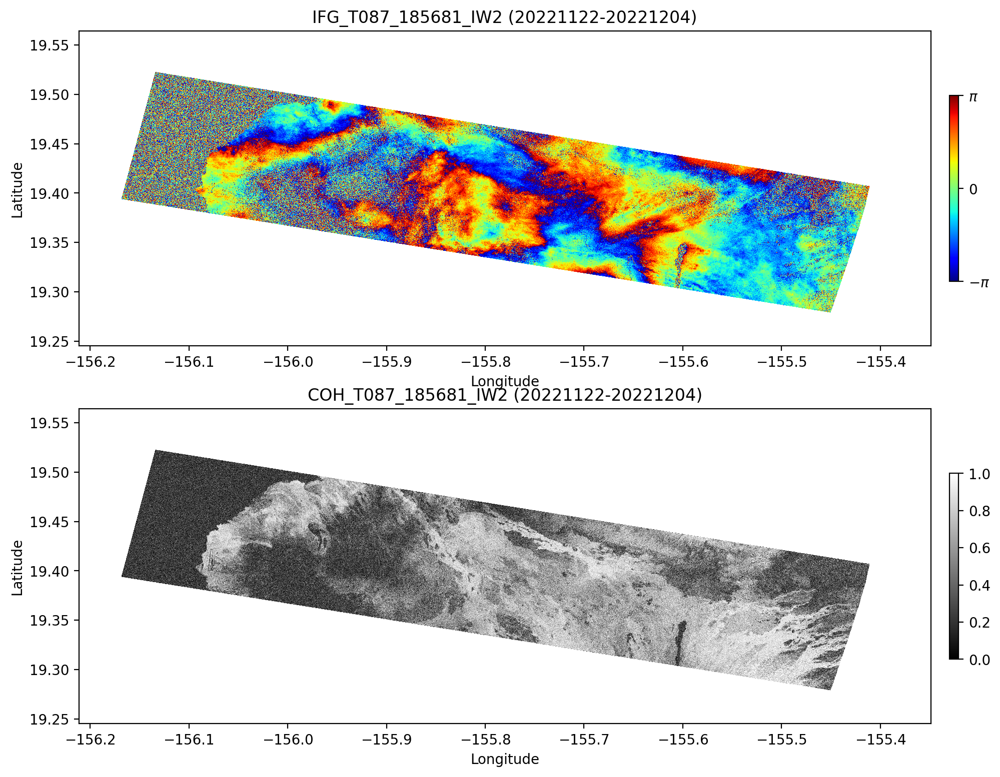

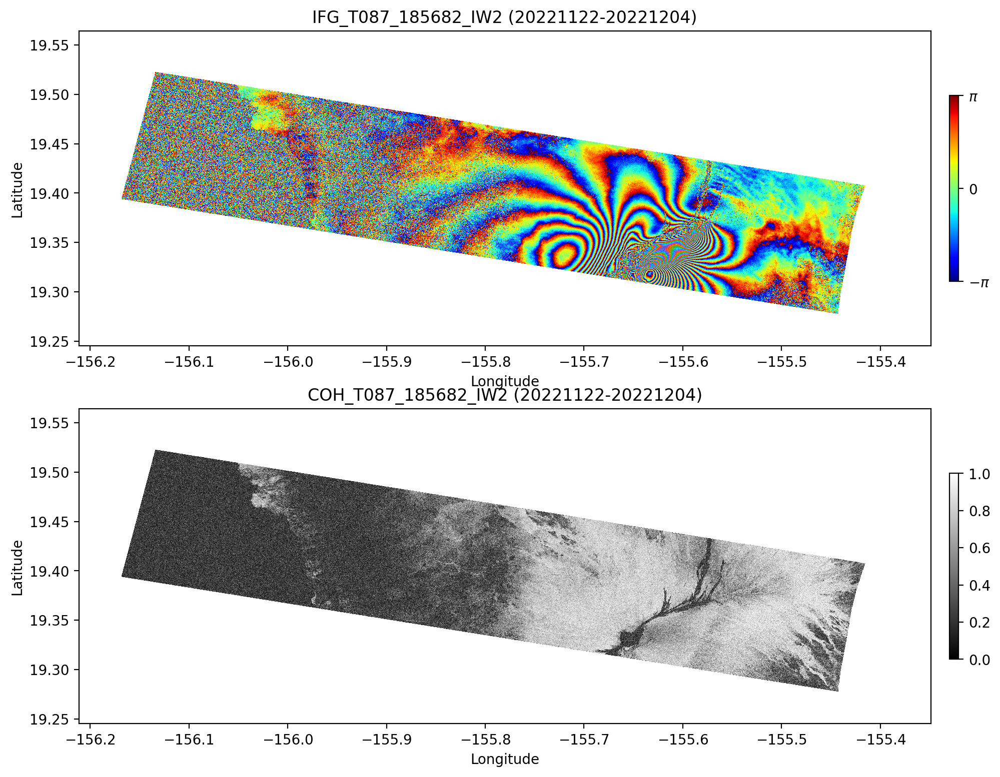

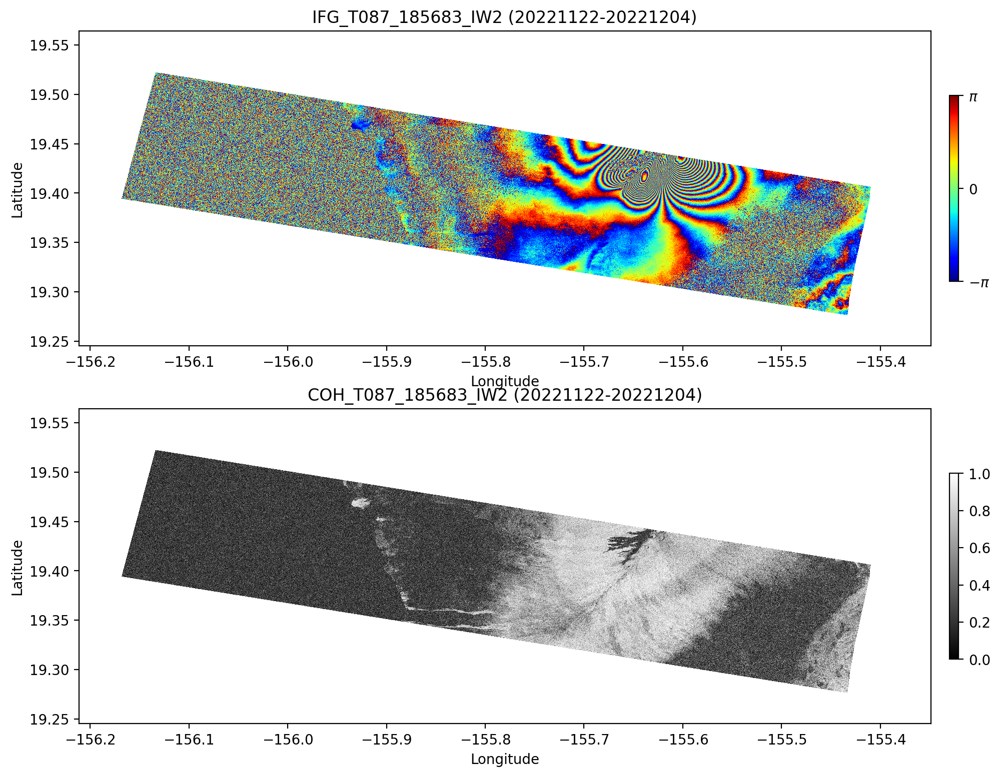

In [20]:
## For each date-pair, calculate the ifg, coh. Save the results as GeoTiffs.
for i in range(0,n_unique_burstID):
    ref_date = cslc_dates.iloc[i].values[0]
    sec_date = cslc_dates.iloc[i+n_unique_burstID].values[0]
    print(f"Reference: {ref_date}  Secondary: {sec_date}")

    # Calculate ifg, coh, amp
    ifg, coh, amp = calc_ifg_coh(cslc_stack[i], cslc_stack[i+n_unique_burstID])
    
    # Plot
    fig, ax = plt.subplots(2,1, figsize=(12,9))
    cax = ax[0].imshow(colorize(ifg, 'jet', -np.pi, np.pi), cmap='jet',interpolation='nearest', origin='upper',extent=bbox, vmin=-np.pi, vmax=np.pi)
    cbar = fig.colorbar(cax,orientation='vertical',fraction=0.01,pad=0.02)
    cbar.set_ticks([-np.pi, 0., np.pi])
    cbar.set_ticklabels([r'$-\pi$', '$0$', r'$\pi$'])
    ax[0].set_xlabel('Longitude')
    ax[0].set_ylabel('Latitude')
    ax[0].set_title(f'IFG_{burstID.iloc[i]} ({ref_date.strftime("%Y%m%d")}-{sec_date.strftime("%Y%m%d")})',fontsize=12)

    cax = ax[1].imshow(coh, cmap='gray',interpolation='nearest', origin='upper',extent=bbox, vmin=0., vmax=1.)
    ax[1].set_xlabel('Longitude')
    ax[1].set_ylabel('Latitude')
    fig.colorbar(cax,orientation='vertical',fraction=0.01,pad=0.02)
    ax[1].set_title(f'COH_{burstID.iloc[i]} ({ref_date.strftime("%Y%m%d")}-{sec_date.strftime("%Y%m%d")})',fontsize=12)

    # Save each interferogram as GeoTiff
    os.makedirs(f'{savedir}/tifs', exist_ok='True')
    transform = from_origin(xcoor_stack[i][0],ycoor_stack[i][0],dx,np.abs(dy))
    rasterWrite(f'{savedir}/tifs/ifg_{burstID.iloc[i]}_{ref_date.strftime("%Y%m%d")}-{sec_date.strftime("%Y%m%d")}.tif',ifg,transform,epsg,dtype=rasterio.float32)
    rasterWrite(f'{savedir}/tifs/coh_{burstID.iloc[i]}_{ref_date.strftime("%Y%m%d")}-{sec_date.strftime("%Y%m%d")}.tif',coh,transform,epsg,dtype=rasterio.float32)

## 8. Merge the burst-wise interferograms and coherence and save as GeoTiff.

In [21]:
def custom_merge(old_data, new_data, old_nodata, new_nodata, **kwargs):    
    mask = np.logical_and(~old_nodata, ~new_nodata)
    old_data[mask] = new_data[mask]
    mask = np.logical_and(old_nodata, ~new_nodata)
    old_data[mask] = new_data[mask]

In [22]:
# Merge burst-wise interferograms
ifg_files = [(f'{savedir}/tifs/ifg_{id}_{ref_date.strftime("%Y%m%d")}-{sec_date.strftime("%Y%m%d")}.tif') for id in burstID]
ifg_files_to_mosaic = []

for f in ifg_files:
    src = rasterio.open(f)
    ifg_files_to_mosaic.append(src)

# Write merged interferogram to GeoTiff
dest, output_transform=merge.merge(ifg_files_to_mosaic, method=custom_merge)
with rasterio.open(ifg_files[0]) as src:
        out_meta = src.meta.copy() 
out_meta.update({"driver": "GTiff",
                 "height": dest.shape[1],
                 "width": dest.shape[2],
                 "transform": output_transform})
with rasterio.open(f"{savedir}/tifs/merged_ifg.tif", "w", **out_meta) as dest1:
        dest1.write(dest)
        dest1.close()


In [23]:
# Merge burst-wise coherence
coh_files = [(f'{savedir}/tifs/coh_{id}_{ref_date.strftime("%Y%m%d")}-{sec_date.strftime("%Y%m%d")}.tif') for id in burstID]
coh_files_to_mosaic = []

for f in coh_files:
    src = rasterio.open(f)
    coh_files_to_mosaic.append(src)

# Write merged coherence to GeoTiff
dest, output_transform=merge.merge(coh_files_to_mosaic, method=custom_merge)
with rasterio.open(coh_files[0]) as src:
        out_meta = src.meta.copy() 
out_meta.update({"driver": "GTiff",
                 "height": dest.shape[1],
                 "width": dest.shape[2],
                 "transform": output_transform})
with rasterio.open(f"{savedir}/tifs/merged_coh.tif", "w", **out_meta) as dest1:
        dest1.write(dest)
        dest1.close()

## 9. Read the merged GeoTiff and Visualize using `matplotlib`

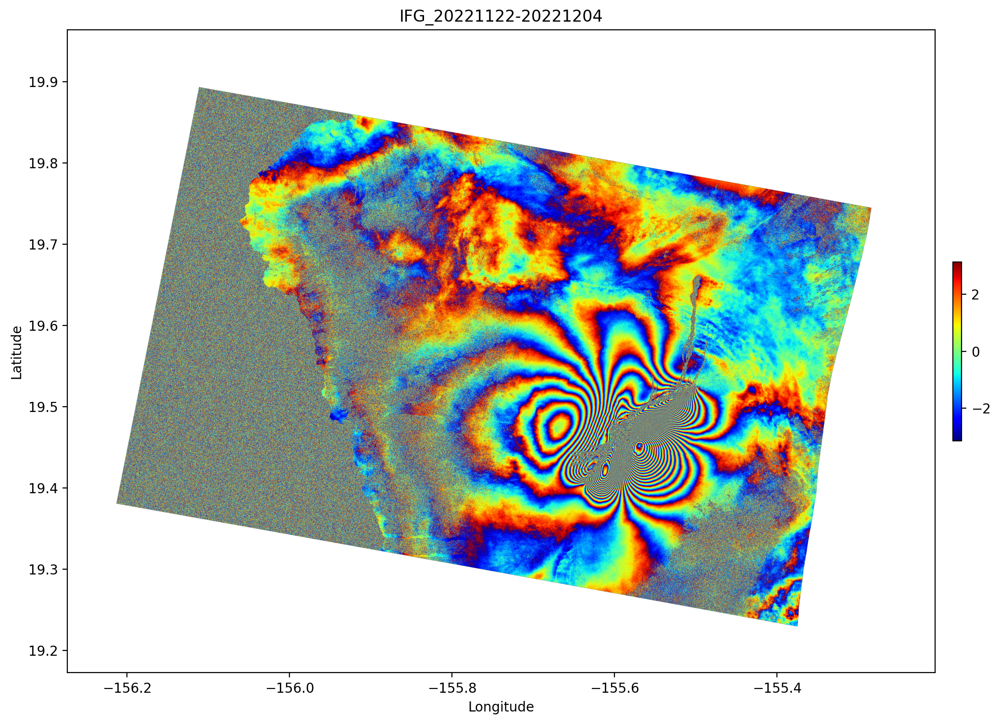

In [24]:
# Read the merged interferogram file
src = rioxarray.open_rasterio(f"{savedir}/tifs/merged_ifg.tif")
merged_ifg = src.rio.reproject("EPSG:4326")[0]             # Folium maps are in EPSG:4326
minlon,minlat,maxlon,maxlat = merged_ifg.rio.bounds()

colored_merged_ifg = colorize(merged_ifg, 'jet', -np.pi, np.pi)

# Define new bounding box
new_bbox = [minlon,maxlon,minlat,maxlat]

# Plot using Matplotlib
fig, ax = plt.subplots(figsize=[12,9])
cax = ax.imshow(colored_merged_ifg, cmap='jet',interpolation=None, origin='upper',extent=new_bbox, vmin=-np.pi, vmax=np.pi)
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
ax.set_title(f'IFG_{ref_date.strftime("%Y%m%d")}-{sec_date.strftime("%Y%m%d")}',fontsize=12)
fig.colorbar(cax,orientation='vertical',fraction=0.01,pad=0.02)
plt.show()

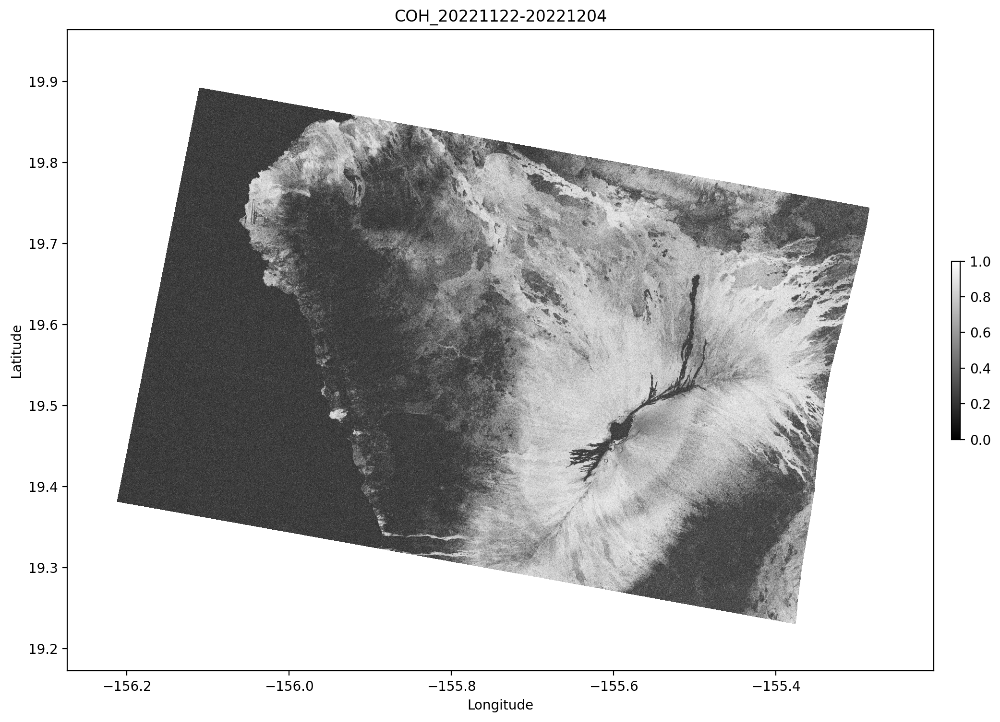

In [25]:
# Read the merged coherence file
src = rioxarray.open_rasterio(f"{savedir}/tifs/merged_coh.tif")
merged_coh = src.rio.reproject("EPSG:4326")[0]             # Folium maps are in EPSG:4326
minlon,minlat,maxlon,maxlat = merged_coh.rio.bounds()

# Define new bounding box
new_bbox = [minlon,maxlon,minlat,maxlat]

# Plot using Matplotlib
fig, ax = plt.subplots(figsize=[12,9])
cax = ax.imshow(merged_coh, cmap='gray',interpolation=None, origin='upper',extent=new_bbox, vmin=0, vmax=1.0)
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
ax.set_title(f'COH_{ref_date.strftime("%Y%m%d")}-{sec_date.strftime("%Y%m%d")}',fontsize=12)
fig.colorbar(cax,orientation='vertical',fraction=0.01,pad=0.02)
plt.show()